# Movie Review Sentiment Analysis
Classify IMDb reviews as **positive** or **negative** using TF-IDF and 4 ML models (Logistic Regression, Naive Bayes, Linear SVM, Decision Tree).

**Steps:** 1. Load data  2. EDA  3. Preprocessing  4. TF-IDF  5. Train & compare models  6. Evaluate  7. Save models for the Streamlit app

## 1. Import libraries

In [1]:
import pandas as pd, numpy as np, re, joblib, sklearn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
sns.set_style("whitegrid")

## 2. Load the dataset


In [2]:
from google.colab import files
uploaded = files.upload()
df = pd.read_csv("IMDB Dataset.csv")
df.head()

Saving IMDB Dataset.csv to IMDB Dataset.csv


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## 3. Exploratory Data Analysis (EDA)

### 3.1 Basic information

In [3]:
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate reviews:", df.duplicated().sum())
df.info()

Shape: (50000, 2)

Missing values:
 review       0
sentiment    0
dtype: int64

Duplicate reviews: 418
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [4]:
# Remove duplicate reviews
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (49582, 2)


### 3.2 Class balance
Checking if positive and negative reviews are equal in number.

sentiment
positive    24884
negative    24698
Name: count, dtype: int64


/tmp/ipykernel_801/1742325356.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="sentiment", data=df, palette="Set2")


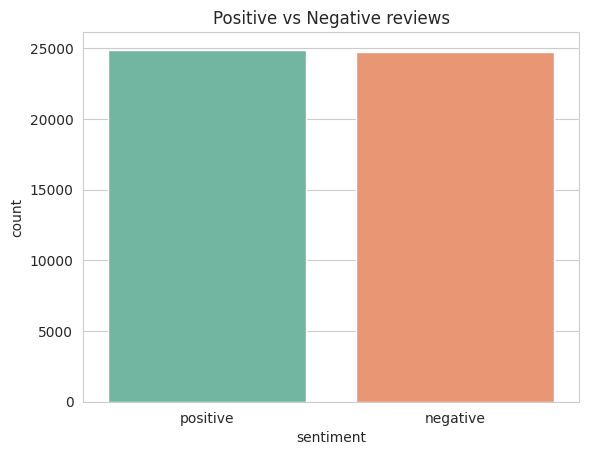

In [5]:
print(df["sentiment"].value_counts())
sns.countplot(x="sentiment", data=df, palette="Set2")
plt.title("Positive vs Negative reviews")
plt.show()

### 3.3 Review length
Do positive and negative reviews differ in length?

             count        mean         std   min    25%    50%    75%     max
sentiment                                                                    
negative   24698.0  229.596607  165.103430   4.0  128.0  174.0  278.0  1522.0
positive   24884.0  233.090620  177.688169  10.0  125.0  172.0  284.0  2470.0


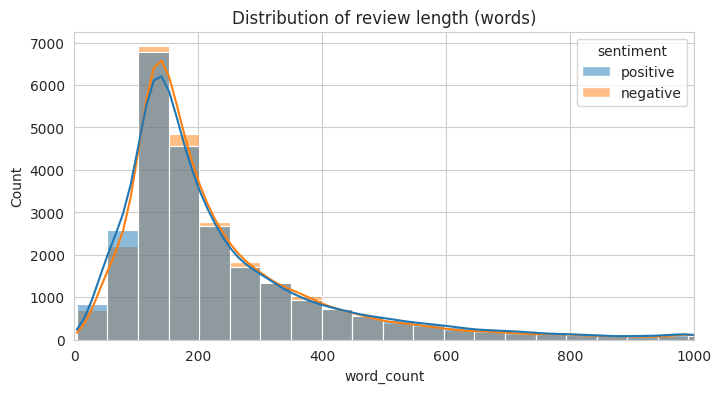

In [6]:
df["word_count"] = df["review"].apply(lambda x: len(x.split()))
print(df.groupby("sentiment")["word_count"].describe())

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="word_count", hue="sentiment", bins=50, kde=True)
plt.xlim(0, 1000)
plt.title("Distribution of review length (words)")
plt.show()

## 4. Text preprocessing
Remove HTML tags (like `<br />`) and convert to lowercase. Stopwords are removed later by TF-IDF.

In [7]:
def clean_text(text):
    text = re.sub(r"<.*?>", " ", text)
    return text.lower()

df["clean_review"] = df["review"].apply(clean_text)
df[["review", "clean_review"]].head(3)

,review,clean_review
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,a wonderful little production. the filming t...
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...


### 4.1 Word clouds
Most frequent words in positive and negative reviews.

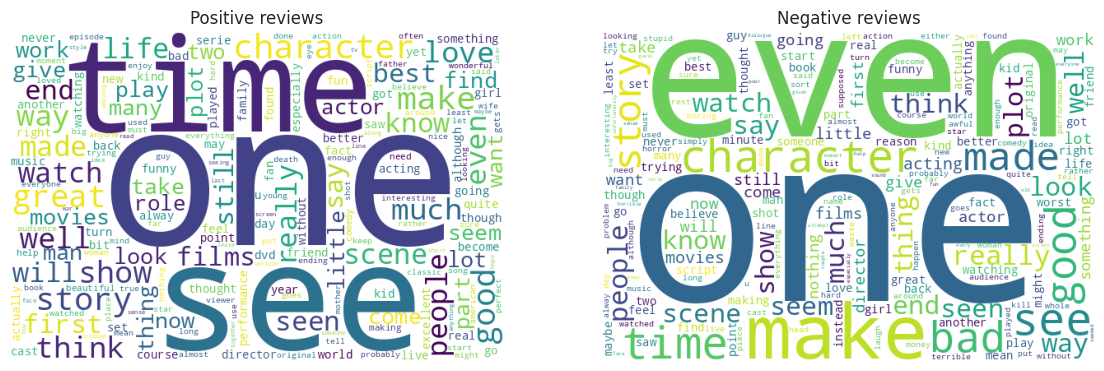

In [8]:
from wordcloud import WordCloud, STOPWORDS
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for i, label in enumerate(["positive", "negative"]):
    text = " ".join(df[df["sentiment"] == label]["clean_review"])
    wc = WordCloud(width=600, height=400, background_color="white",
                   stopwords=STOPWORDS.union({"br", "movie", "film"})).generate(text)
    ax[i].imshow(wc)
    ax[i].set_title(label.capitalize() + " reviews")
    ax[i].axis("off")
plt.show()

## 5. Feature extraction using TF-IDF
TF-IDF converts text into numbers. We split the data 80% train / 20% test.

In [9]:
y = (df["sentiment"] == "positive").astype(int)   # positive = 1, negative = 0
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_review"], y, test_size=0.2, random_state=42, stratify=y)

vec = TfidfVectorizer(stop_words="english", max_features=20000, ngram_range=(1, 2))
Xtr = vec.fit_transform(X_train)
Xte = vec.transform(X_test)
print("Train shape:", Xtr.shape, " Test shape:", Xte.shape)

Train shape: (39665, 20000)  Test shape: (9917, 20000)


## 6. Train and compare models

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(),
    "Decision Tree": DecisionTreeClassifier(max_depth=50, random_state=42),
}

results, preds, accs = [], {}, {}
for name, m in models.items():
    m.fit(Xtr, y_train)
    p = m.predict(Xte)
    preds[name] = p
    accs[name] = round(accuracy_score(y_test, p), 4)
    results.append([name, accuracy_score(y_test, p), precision_score(y_test, p),
                    recall_score(y_test, p), f1_score(y_test, p)])

results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1-score"])
results_df = results_df.sort_values("Accuracy", ascending=False).reset_index(drop=True)
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.8964,0.8856,0.9114,0.8983
1,Linear SVM,0.8900,0.8867,0.8951,0.8909
2,Naive Bayes,0.8693,0.8622,0.8802,0.8711
3,Decision Tree,0.7387,0.7258,0.7705,0.7475


### 6.1 Accuracy comparison

/tmp/ipykernel_801/439749385.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Accuracy", y="Model", data=results_df, palette="viridis")


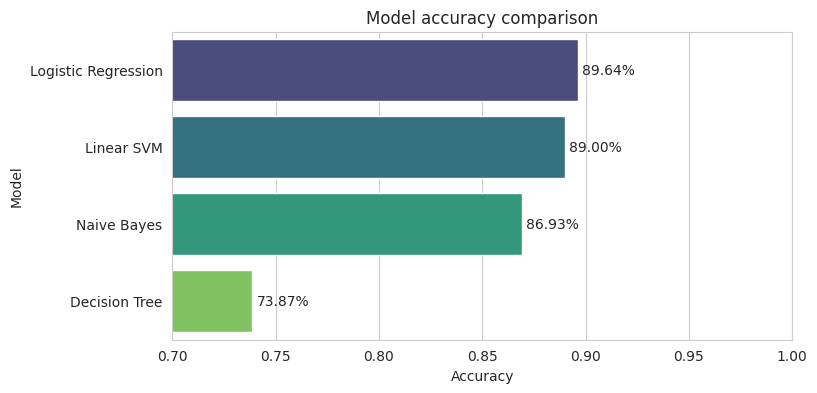

In [11]:
plt.figure(figsize=(8, 4))
sns.barplot(x="Accuracy", y="Model", data=results_df, palette="viridis")
plt.xlim(0.7, 1)
for i, v in enumerate(results_df["Accuracy"]):
    plt.text(v + 0.002, i, f"{v*100:.2f}%", va="center")
plt.title("Model accuracy comparison")
plt.show()

## 7. Evaluation

### 7.1 Confusion matrices
Shows how many reviews each model classified correctly and wrongly.

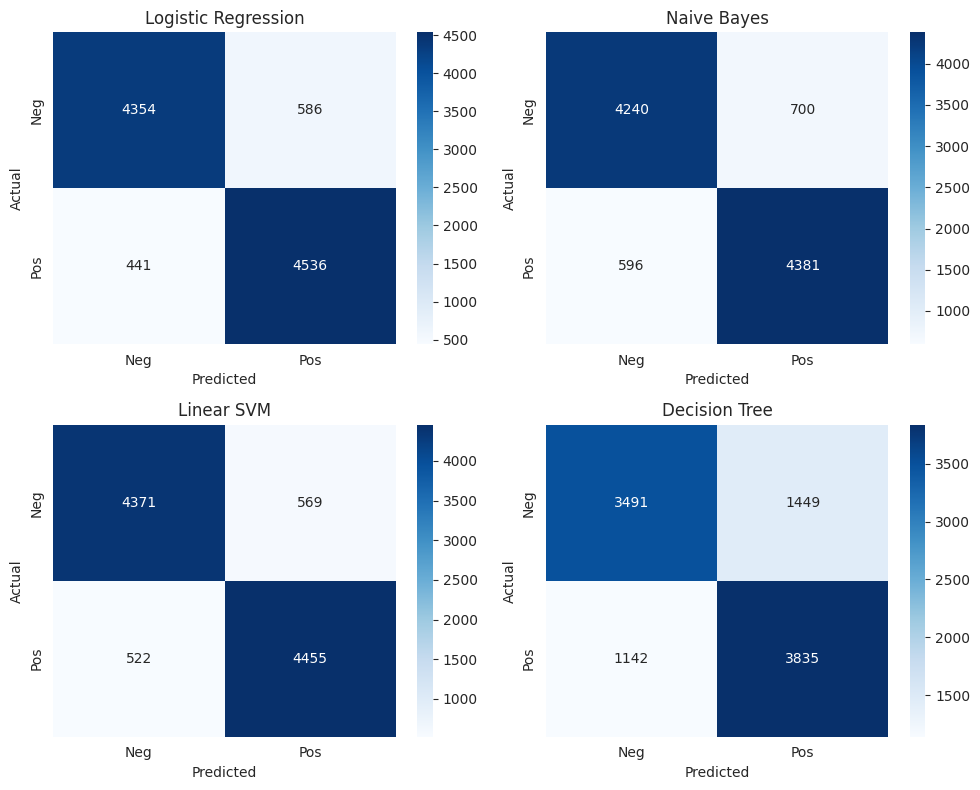

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (name, p) in zip(axes.ravel(), preds.items()):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

### 7.2 Classification report of the best model

In [13]:
best = results_df.loc[0, "Model"]
print("Best model:", best)
print(classification_report(y_test, preds[best], target_names=["Negative", "Positive"]))

Best model: Logistic Regression
              precision    recall  f1-score   support

    Negative       0.91      0.88      0.89      4940
    Positive       0.89      0.91      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



### 7.3 Most important words (Logistic Regression)
Words the model uses most to decide positive or negative.

In [14]:
lr = models["Logistic Regression"]
words = np.array(vec.get_feature_names_out())
order = np.argsort(lr.coef_[0])
top_neg, top_pos = words[order[:15]], words[order[-15:]]
print("Top NEGATIVE words:", list(top_neg))
print("Top POSITIVE words:", list(top_pos))

Top NEGATIVE words: ['worst', 'awful', 'bad', 'boring', 'waste', 'poor', 'terrible', 'worse', 'horrible', 'dull', 'poorly', 'fails', 'disappointment', 'annoying', 'lame']
Top POSITIVE words: ['superb', 'hilarious', 'love', 'enjoyed', 'fun', 'today', 'brilliant', 'loved', 'favorite', 'wonderful', 'amazing', 'perfect', 'best', 'excellent', 'great']


## 8. Test with your own reviews

In [15]:
def predict_review(text, model_name="Logistic Regression"):
    X = vec.transform([clean_text(text)])
    return "Positive" if models[model_name].predict(X)[0] == 1 else "Negative"

tests = ["This movie was absolutely fantastic, great acting!",
         "Terrible film. Boring and a complete waste of time."]
for t in tests:
    print(t, "->", {n: predict_review(t, n) for n in models})

This movie was absolutely fantastic, great acting! -> {'Logistic Regression': 'Positive', 'Naive Bayes': 'Positive', 'Linear SVM': 'Positive', 'Decision Tree': 'Positive'}
Terrible film. Boring and a complete waste of time. -> {'Logistic Regression': 'Negative', 'Naive Bayes': 'Negative', 'Linear SVM': 'Negative', 'Decision Tree': 'Negative'}


## 9. Save the models for the Streamlit app
This downloads 3 files. Put them in the same folder as `app.py`.

In [16]:
joblib.dump(vec, "tfidf_vectorizer.joblib")
joblib.dump(models, "all_models.joblib")
joblib.dump(accs, "accuracies.joblib")
print("scikit-learn version:", sklearn.__version__)

files.download("tfidf_vectorizer.joblib")
files.download("all_models.joblib")
files.download("accuracies.joblib")

scikit-learn version: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion
- The dataset is balanced (equal positive and negative reviews).
- TF-IDF with unigrams and bigrams gives good features for text.
- Linear models (Logistic Regression, Linear SVM) perform best; Decision Tree performs worst on high-dimensional text data.
- Naive Bayes is the fastest and a strong baseline.